# Representation study: compression, clustering, and supported claims

## 1. Introduction and learning objectives

Build a small research study, not a collection of attractive scatterplots. The question is: **under a fixed three-prototype compression budget, how do representation and training initialization affect independently measured reconstruction and partition stability?** A good answer specifies the population, geometry, optimization budget, selection boundary and limitations. It does not equate a low compression error, stable partition or high agreement with existing labels with the discovery of a uniquely correct taxonomy.

Implement training-fitted PCA and centroid learning manually with NumPy. Compare a mean baseline and six fixed representation procedures on a generated mixture, a single-Gaussian null and the licensed offline Iris artifact. Select using an explicit common validation loss, freeze every fitted model and the selected procedure, calibrate its reconstruction score on separate rows, and evaluate one final panel. Keep all starts, failed stopping targets, sensitivity studies, numeric checkpoints and uncertainty assumptions. All learner answers are blank; collapsed references form one auditable local implementation, not package APIs.

**Prerequisites:** all five [Stage 03 chapters](../../notebooks/03-unsupervised-learning/README.md), Stage 00 numerical/probability tools and Stage 01 evaluation. The [Iris notice](../../src/ml_from_scratch/data/NOTICE.md) records its attribution, license, hash, source discrepancies and duplicate rows. No download, GPU or new dependency is required. Submit a completed study notebook, independent checks, checkpoints and a report based on the [blank template](report-template.md) on your own study branch. Default CI executes demonstrations and author checks, not unfinished learner implementations or a personal mastery grade.

## 2. Prerequisites and mathematical foundations

Training observations are rows of $X\in\mathbb R^{n\times d}$. Fit mean $\mu\in\mathbb R^d$ and two scales on **training only**: the procedure's coordinate scale $s$ and a common reporting scale $t$. Raw procedures use $s_j=1$; standardized procedures use the training population standard deviation. The reporting scale $t$ is always that same training standard deviation, with one for constant coordinates. This is an invertible unit convention, not evidence that every feature deserves equal scientific weight.

Let $B=(X-\mu)/s$ and let $V\in\mathbb R^{d\times r}$ have orthonormal columns. Identity procedures use $r=d,V=I$; PCA procedures keep one or two training-fitted right singular vectors. Coordinates are $Z=BV$. K-means fits three centers in this coordinate system by minimizing **sum SSE** $\sum_i\|z_i-c_{a_i}\|^2$. For a new row, assign its nearest center with first-index ties and reconstruct
$$\hat x_i=\mu+(c_{a_i}V^T)\odot s.$$
The **common per-row loss** used for validation and final reporting is
$$L_i=\frac1d\sum_{j=1}^d\left(\frac{x_{ij}-\hat x_{ij}}{t_j}\right)^2.$$
It averages features once, and a reported mean then averages observations once. All procedures share the same $t$, original features and held-out rows. The training-mean baseline reconstructs $\mu$ for every row. Its training mean loss is one when all training features have positive variance; constant columns contribute zero. A lower score supports this declared compression task, not necessarily latent-class recovery.

The model's training SSE, PCA explained-variance ratio and common loss are different quantities. For example, discarding coordinates trivially removes their contribution from latent-space SSE. Comparing that SSE across retained dimensions rewards omission rather than complete reconstruction. Labels play no role in preprocessing, initialization, selection or calibration. Synthetic component IDs and Iris species are revealed only in the frozen final panel for an explicitly external agreement audit; they are not automatically the right target for unsupervised compression.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 03.P.01 — Preregister the question, budget, and information boundaries

**Type:** Conceptual · **Answer:** Markdown

State the primary compression question, common metric, seven candidate procedures, baseline, fixed cluster budget, initialization budget and tie rules. Draw the flow of training, validation, calibration and final data. Explain why using species labels to choose a PCA dimension would be supervised selection even if every fit uses K-means.

**Expected outcome:** a falsifiable protocol distinguishing optimization, selection, score calibration and final external-label interpretation.

**Your response to Exercise 03.P.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.01**

The fixed cluster budget is an engineering constraint, not an estimate of a population's number of categories. A label can leak through a design choice as well as an update.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.01**

The primary outcome is common feature-averaged reconstruction loss on independent rows under a three-prototype budget. Candidate order is mean, raw identity, raw PCA-1, raw PCA-2, standardized identity, standardized PCA-1 and standardized PCA-2. Each nonbaseline procedure gets four random distinct-row starts and four D-squared starts, each with at most 100 Lloyd updates. Choose a start by its own training-coordinate SSE, then select a procedure by common validation mean loss; ties use declared order. Fit all transforms on training only, freeze after validation, use a separate nominal calibration split for a reconstruction-score threshold, and evaluate every frozen procedure in one final panel. Labels may appear in that final descriptive audit only. Choosing representation or cluster count after inspecting label agreement would change this into supervised selection and consume that information boundary.

</details>

## 3. Theoretical development and worked examples

### Orthogonality does not survive every change of metric

Let $P=VV^T$. In model coordinates,
$$B-\hat B=(B-BP)+(BV-C)V^T,$$
where $C$ contains the assigned centers. The two terms are Frobenius-orthogonal because $(B-BP)V=0$, giving a projection residual plus a quantization residual in the **unweighted model-coordinate** squared norm. Common reporting instead right-multiplies both residuals by $A=\operatorname{diag}(s/t)$. In general, the transformed residuals are not orthogonal; their cross term need not vanish. Therefore do not add a latent SSE and discarded eigenvalue sum and call that the common error. Reconstruct complete original rows and calculate the declared loss directly. The decomposition remains valid in the matching metric, including standardized procedures for which $s=t$.

For fixed assignments, $J(C)=\sum_i\|z_i-c_{a_i}\|^2$ has gradient $2\sum_{i:a_i=j}(c_j-z_i)$ with respect to center $j$. There is no $1/n$ factor in this sum objective. Lloyd assignment and mean updates decrease this objective; stable labels do not establish a global optimum, semantic recovery or an optimal common loss for a differently weighted raw procedure. Empty centers use the explicit keep policy and are reported. Budget exhaustion is an outcome, not a reason to drop a start.

### A finite hand audit and a probabilistic distinction

For $x=(0,2,8,10)$, two initial centers $(0,8)$ give SSE eight, then means $(1,9)$ and SSE four. Training mean is five and variance under divisor $n$ is 17. In one feature the mean baseline has common training loss one; the two-center reconstruction has loss $1/17$. This is not a theorem that every finite restart reaches the best partition.

For fixed uniform mixture weights, common spherical variance $\sigma^2$ and **hard** assignments, negative joint Gaussian log density equals a constant plus SSE divided by $2\sigma^2$. The **marginal** mixture log likelihood instead contains a log-sum over assignments and gives soft responsibilities. For one point zero, means $(-1,1)$ and variance one, marginal NLL is $(1+\log(2\pi))/2\approx1.41893853$; either hard joint NLL is larger by $\log2$, about $2.11208571$. A deterministic centroid assignment is not a posterior responsibility, and its reconstruction residual is not a normalized input density. These distinctions prevent treating an unsupervised objective as an arbitrary probability forecast.

### Stability and uncertainty name their source of randomness

Assess initialization sensitivity by extending every fitted restart's nearest-center rule to the **same validation rows** and comparing partitions with adjusted Rand index (ARI). Raw cluster IDs are arbitrary, so direct label equality is inappropriate. Separately bootstrap only training rows, refit a frozen procedure, and compare its validation assignments with the original procedure's assignments. These perturb different objects. Neither is a universal confidence interval for semantic clusters, and a mean-only partition is trivially stable.

After freezing a score $S(x)=L(x)$, the conservative split-conformal p-value is $(1+\#\{S_i^{cal}\ge S(x)\})/(c+1)$. A predeclared alpha .1 controls marginal nominal false alarms under exchangeability conditional on the independent fitted score. It does not turn $L$ into a density or guarantee conditional-on-calibration validity. Iris is a finite convenience artifact with dependent duplicate records and an unknown sampling process; its threshold counts are descriptive unless those assumptions receive separate justification.

For IID final flags conditional on a realized model and threshold, one may additionally **model** an unknown flag probability $\theta$ using a Beta$(a,b)$ prior and Bernoulli likelihood. With $f$ flags among $N$ final rows, the posterior is Beta$(a+f,b+N-f)$, with predictive mean $(a+f)/(a+b+N)$. This is a model-based conditional summary, not the conformal guarantee and not uncertainty over newly drawn training/calibration sets. Do not attach an IID posterior interpretation to Iris merely because the algebra is computable.

### Exercise 03.P.02 — Derive the metric and the objective checks

**Type:** Mathematical · **Answer:** Markdown

Derive the model-space orthogonal decomposition and explain why a nonuniform reporting metric can introduce a cross term. Derive the fixed-assignment center gradient, the hard versus marginal Gaussian objective distinction, and the conditioning behind a Beta summary of final flags.

**Expected outcome:** correct shapes/scaling, an explicit metric assumption, no hard-assignment posterior claim, and separate model-based and rank-based probabilities.

**Your response to Exercise 03.P.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.02**

Right multiplication by a diagonal metric need not preserve orthogonality. The negative log of a sum is not the minimum of negative logs.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.02**

Write $R=B-BVV^T$ and $T=(BV-C)V^T$. Since $RV=0$, their Frobenius inner product is zero. Under right multiplication by $A$, the cross term becomes $2\operatorname{tr}(A^TR^TTA)$ and can be nonzero. Thus direct full-row reconstruction is required for the common weighted metric. Differentiating the sum center loss gives twice each occupied cluster's displacement sum; an empty center's gradient is zero under its current assignment. Fixed spherical hard joint likelihood has SSE plus weight/normalization terms, whereas marginal mixture likelihood integrates assignments using log-sum-exp. A Beta update conditions on the prior and an IID Bernoulli model for final flags under the realized detector; it neither estimates the randomness of a new calibration threshold nor replaces a finite-rank theorem. These are distinct mathematical claims even if both report numbers near a nominal level.

</details>

### Exercise 03.P.03 — Reproduce the hand loss and a coordinate counterexample

**Type:** Numerical · **Answer:** Markdown

Compute the one-dimensional hand SSEs, common losses and two Gaussian NLLs above. Then use orthogonal vectors $r=(1,1)$ and $q=(1,-1)$ and reporting matrix $A=\operatorname{diag}(2,1)$ to demonstrate that their transformed cross term is nonzero.

**Expected outcome:** SSE eight then four, common losses one and $1/17$, a $\log2$ likelihood gap, and transformed inner product three.

**Your response to Exercise 03.P.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.03**

The original dot product is zero; after transformation the vectors are $(2,1)$ and $(2,-1)$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.03**

The initial squared distances are $(0,4,0,4)$ and final distances are all one. Dividing final SSE four by four observations and training variance 17 gives $1/17$; baseline centered SSE 68 gives one. The mixture's two equal half-weighted densities sum to the same density as either component, while a hard joint choice retains its factor one half and adds $\log2$ to NLL. Finally $(rA)\cdot(qA)=4-1=3$, so the cross term in the squared combined norm is six. Orthogonality in one coordinate metric cannot justify a decomposition in another.

</details>

## 4. Guided exercises

### Exercise 03.P.04 — Generate offline tasks and split whole duplicate groups

**Type:** Programming · **Answer:** Code

Implement the three fixed tasks and a label-free group partition. Synthetic tasks each have 360 IID rows in four features; the null is one Gaussian, not hidden discrete classes. Group identical feature rows by first occurrence before splitting. With seed 30601, allocate shuffled groups approximately 50/20/15/15 to training, validation, calibration and final sets, without stratifying on labels. Record actual row counts and prevent all group overlap.

**Expected outcome:** deterministic local data, preserved Iris quirks, complete disjoint partitions, and no use of labels in fitting or splitting.

In [ ]:
# Your code for Exercise 03.P.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.04**

Split groups, then expand them to row indices. Duplicate feature grouping is a declared protection, not proof that every distinct row is an independent entity.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.04**

The only package call below is the existing licensed offline data loader. Synthetic component assignments are sampled independently for each row. Features deliberately combine a low-scale mixture signal, nuisance and a correlated measurement. The null uses a nonsingular Gaussian with no discrete generating label. The arbitrary three-prototype budget is fixed for all tasks and is not inferred from Iris species. First-occurrence group IDs are row indices when all rows are distinct, so a fixed split seed does not select predetermined feature ranks. Grouping and splitting dependent/duplicated artifacts still does not establish IID sampling; unobserved entity dependence would require additional identifiers in a different study.

~~~python
from ml_from_scratch.datasets import load_iris

def study_rows(values, name='rows', empty=False):
    x = np.asarray(values,dtype=float)
    if x.ndim != 2 or not 1 <= x.shape[1] <= 16 or len(x) > 2000 or (not empty and len(x) == 0) or not np.isfinite(x).all():
        raise ValueError(name+' requires finite bounded rows and 1..16 features')
    return x

def study_groups(values):
    x = study_rows(values)
    _,first,inverse = np.unique(x,axis=0,return_index=True,return_inverse=True)
    remap = np.empty(len(first),dtype=np.int64)
    remap[np.argsort(first)] = np.arange(len(first))
    return remap[inverse]

def study_datasets():
    rng = np.random.default_rng(30600)
    labels = rng.integers(0,3,size=360)
    signal = np.array([-2.,0.,2.])[labels]+.25*rng.normal(size=360)
    mixture = np.column_stack((signal,5*rng.normal(size=360),.6*rng.normal(size=360),.4*signal+.2*rng.normal(size=360)))
    rng_null = np.random.default_rng(30609)
    base = rng_null.normal(size=(360,4))
    null = base@np.array([[1.,0.,0.,.3],[0.,4.,0.,0.],[0.,0.,.6,0.],[0.,0.,0.,.5]])
    iris,iris_labels = load_iris()
    return {name:dict(name=name,X=x.copy(),audit_labels=None if y is None else y.copy(),groups=study_groups(x))
            for name,x,y in [('mixture',mixture,labels),('gaussian_null',null,None),('iris',iris,iris_labels)]}

def study_partition(groups, seed=30601):
    groups = np.asarray(groups)
    if groups.ndim != 1 or groups.dtype.kind not in 'iu' or not 8 <= len(groups) <= 2000:
        raise ValueError('8..2000 integer group labels required')
    unique = np.unique(groups)
    if len(unique) < 8:
        raise ValueError('at least eight distinct groups required')
    shuffled = np.random.default_rng(seed).permutation(unique)
    cuts = [len(unique)*percentage//100 for percentage in (50,70,85)]
    return tuple(np.flatnonzero(np.isin(groups,piece)) for piece in np.split(shuffled,cuts))
~~~

</details>

### Exercise 03.P.05 — Fit and invert each representation using training only

**Type:** Programming · **Answer:** Code

Implement the coordinate transform, identity/PCA maps and reconstruction. Use population standard deviations and scale one for a truly constant coordinate. Keep a separate common reporting scale. Record the spectrum, retained variance and the exact fitted arrays. Do not whiten or silently discard constant features. Check null/rank-deficient cases and held-out outliers.

**Expected outcome:** correct train-only shapes and inverse reconstruction, explicit PCA metric conventions, and identical reporting scales across candidate procedures.

In [ ]:
# Your code for Exercise 03.P.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.05**

Thin SVD is a numerical primitive. Keep its right singular vectors as columns and fix signs only for repeatable display, not to claim a unique basis at tied singular values.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.05**

This snippet depends on 03.P.04. The sign convention takes the largest absolute coordinate of each retained vector as positive. Tied subspaces can still have nonunique bases; reconstructors and projectors are the appropriate invariant checks. A lost scale for a nonconstant feature raises rather than inventing a safe-looking transform. The arithmetic/work caps are pedagogical bounds, not high-dimensional PCA infrastructure.

~~~python
def study_fit_coordinates(train):
    x = study_rows(train)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        mean = x.mean(axis=0); scale = np.sqrt(np.mean((x-mean)**2,axis=0))
    constant = np.all(x == x[0],axis=0)
    if np.any((scale <= 0)&~constant) or not np.isfinite(scale).all():
        raise FloatingPointError('nonconstant reporting scale vanished')
    scale[constant] = 1.
    return mean.copy(),scale.copy()

def study_specifications():
    return [dict(name='mean',mode='mean',components=None),
            dict(name='raw_identity',mode='raw',components=None),
            dict(name='raw_pca_1',mode='raw',components=1),dict(name='raw_pca_2',mode='raw',components=2),
            dict(name='standardized_identity',mode='standardized',components=None),
            dict(name='standardized_pca_1',mode='standardized',components=1),dict(name='standardized_pca_2',mode='standardized',components=2)]

def study_fit_representation(train, spec):
    x = study_rows(train); mean,reference_scale = study_fit_coordinates(x)
    if spec['mode'] not in ('mean','raw','standardized'):
        raise ValueError('unknown representation mode')
    scale = reference_scale.copy() if spec['mode'] == 'standardized' else np.ones(x.shape[1])
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        b = (x-mean)/scale
        _,singular,vt = np.linalg.svd(b,full_matrices=False)
        spectrum = singular**2/len(x)
    retained = spec['components']
    if retained is None:
        axes = np.eye(x.shape[1]); ratio = 1. if spectrum.sum() > 0 else None
    else:
        if isinstance(retained,(bool,np.bool_)) or not isinstance(retained,(int,np.integer)) or not 1 <= retained <= min(x.shape):
            raise ValueError('invalid retained dimension')
        axes = vt[:retained].T.copy()
        for j in range(axes.shape[1]):
            if axes[np.argmax(np.abs(axes[:,j])),j] < 0:
                axes[:,j] *= -1
        ratio = float(spectrum[:retained].sum()/spectrum.sum()) if spectrum.sum() > 0 else None
    return dict(spec=dict(spec),mean=mean,scale=scale,reference_scale=reference_scale,
                axes=axes,spectrum=spectrum,retained_ratio=ratio,fit_n=len(x))

def study_coordinates(model, queries):
    x = study_rows(queries,empty=True)
    if x.shape[1] != len(model['mean']):
        raise ValueError('fitted/query feature mismatch')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        result = ((x-model['mean'])/model['scale'])@model['axes']
    if not np.isfinite(result).all():
        raise FloatingPointError('nonfinite representation')
    return result
~~~

</details>

### Exercise 03.P.06 — Implement bounded centroid optimization and all start records

**Type:** Programming · **Answer:** Code

Implement direct squared distances, sum-SSE/center gradients, random or D-squared initialization, and Lloyd updates. Use smallest-center computed ties, distinct initial row indices and the keep-empty policy. Keep the objective trace, initial rows, final centers, iterations, empty-cluster count, gradient norm and stable-label versus budget status for every start. Permit a zero-step budget for a deliberate unfinished diagnostic.

**Expected outcome:** independent gradients/hand optima, nonincreasing traces, no missing empty/budget cases, and explicit arithmetic failure rather than silent rescue.

In [ ]:
# Your code for Exercise 03.P.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.06**

At a stable-label stop, the updated nonempty centers are means of the same assignments. At budget exhaustion they need not be means of the final reassigned labels.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.06**

This snippet depends on 03.P.04. Blocks accumulate squared feature differences without a three-axis tensor. Returned distances still occupy an $n\times k$ matrix. If D-squared potential is numerically zero, take the first unused row; this can still duplicate a location and leave empty centers. A nonfinite calculation raises and stops the run, so an unsuccessful computation cannot be reported as a completed comparison. Preserve the last completed checkpoint and disclose such failures. Budget-exhausted starts remain ordinary recorded candidates.

~~~python
def study_squared_distances(queries, centers, block=64):
    q = study_rows(queries,empty=True); c = study_rows(centers)
    if q.shape[1] != c.shape[1] or isinstance(block,(bool,np.bool_)) or not isinstance(block,(int,np.integer)) or not 1 <= block <= 256:
        raise ValueError('matching features and block in 1..256 required')
    result = np.empty((len(q),len(c)))
    with np.errstate(over='raise',invalid='raise'):
        for start in range(0,len(q),block):
            end = min(start+block,len(q)); squared = np.zeros((end-start,len(c)))
            for j in range(q.shape[1]):
                difference = q[start:end,j,None]-c[None,:,j]
                squared += difference*difference
            result[start:end] = squared
    if not np.isfinite(result).all():
        raise FloatingPointError('distance arithmetic range exceeded')
    return result

def study_centroid_objective(values, centers, labels):
    z = study_rows(values); c = study_rows(centers); labels = np.asarray(labels)
    if z.shape[1] != c.shape[1] or labels.shape != (len(z),) or labels.dtype.kind not in 'iu' or np.any((labels < 0)|(labels >= len(c))):
        raise ValueError('invalid fixed assignments')
    with np.errstate(over='raise',invalid='raise'):
        residual = z-c[labels]; value = float(np.sum(residual**2))
        gradient = np.zeros_like(c)
        np.add.at(gradient,labels,-2*residual)
    return value,gradient

def study_kmeans(values, k=3, initialization='random', seed=30602, max_steps=100, initial_indices=None):
    z = study_rows(values)
    if isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 1 <= k <= min(len(z),8):
        raise ValueError('1..8 centers no more than training rows required')
    if initialization not in ('random','d_squared') or isinstance(max_steps,(bool,np.bool_)) or not isinstance(max_steps,(int,np.integer)) or not 0 <= max_steps <= 200:
        raise ValueError('declared initialization and 0..200 steps required')
    rng = np.random.default_rng(seed)
    if initial_indices is not None:
        chosen = np.asarray(initial_indices)
        if chosen.shape != (k,) or chosen.dtype.kind not in 'iu' or len(np.unique(chosen)) != k or np.any((chosen < 0)|(chosen >= len(z))):
            raise ValueError('distinct valid initial row indices required')
        chosen = chosen.tolist()
    elif initialization == 'random':
        chosen = rng.choice(len(z),size=k,replace=False).tolist()
    else:
        chosen = [int(rng.integers(len(z)))]
        for _ in range(1,k):
            nearest = study_squared_distances(z,z[chosen]).min(axis=1)
            with np.errstate(over='raise',invalid='raise'):
                total = float(nearest.sum())
            if total == 0.:
                index = next(i for i in range(len(z)) if i not in chosen)
            else:
                index = int(rng.choice(len(z),p=nearest/total))
            chosen.append(index)
    centers = z[chosen].copy(); distances = study_squared_distances(z,centers)
    labels = distances.argmin(axis=1)
    with np.errstate(over='raise',invalid='raise'):
        trace = [float(distances[np.arange(len(z)),labels].sum())]
    stable = False
    for _ in range(max_steps):
        updated = centers.copy()
        for j in range(k):
            if np.any(labels == j):
                updated[j] = z[labels == j].mean(axis=0)
        distances = study_squared_distances(z,updated); new_labels = distances.argmin(axis=1)
        with np.errstate(over='raise',invalid='raise'):
            trace.append(float(distances[np.arange(len(z)),new_labels].sum()))
        stable = bool(np.array_equal(new_labels,labels))
        centers,labels = updated,new_labels
        if stable:
            break
    value,gradient = study_centroid_objective(z,centers,labels)
    return dict(centers=centers.copy(),initial_indices=chosen,trace=trace,
                training_sse=value,iterations=len(trace)-1,status='stable_labels' if stable else 'budget_exhausted',
                empty_centers=int(np.sum(np.bincount(labels,minlength=k) == 0)),
                gradient_norm=float(np.linalg.norm(gradient)),initialization=initialization,seed=int(seed))
~~~

</details>

## 5. Implementation challenges

### Exercise 03.P.07 — Fit seven candidates and select only on common validation loss

**Type:** Programming · **Answer:** Code

Implement the fixed model adapters, complete-row reconstruction, validation loss table and selector. Each nonbaseline gets the same eight seed positions: four starts of each declared initialization. Select a start by training SSE within its representation, then select a procedure by common validation mean loss. Keep every model and start, including unfinished diagnostics, and never pass calibration, final rows or labels to selection.

**Expected outcome:** deterministic candidate order, common comparable losses, train-only transformations, first-minimum decisions and complete optimizer evidence.

In [ ]:
# Your code for Exercise 03.P.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.07**

A lower raw-coordinate SSE is not a lower common loss. Retain the actual reconstructed rows and independently recompute at least one scalar loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.07**

This snippet depends on 03.P.04–06. Repeated seeds couple start positions across representations without claiming that D-squared probabilities are the same in different geometries. Every run's final centers stay in its record for later initialization sensitivity. Wall times are measured, not deterministic test targets. The fixed cluster budget is three for all nonbaseline fits. All six get eight starts even if an earlier start already looks good.

~~~python
import time

def study_fit_model(train, spec, seed=30602, max_steps=100):
    model = study_fit_representation(train,spec); z = study_coordinates(model,train)
    if spec['mode'] == 'mean':
        model.update(centers=np.zeros((1,z.shape[1])),runs=[],chosen_run=None)
        return model
    seeds = np.random.SeedSequence(seed).generate_state(8)
    runs = []
    for index,child in enumerate(seeds):
        run = study_kmeans(z,3,'random' if index < 4 else 'd_squared',int(child),max_steps)
        run['centers'] = run['centers'].tolist()
        runs.append(run)
    chosen = int(np.argmin([run['training_sse'] for run in runs]))
    model.update(centers=np.array(runs[chosen]['centers'],dtype=float),runs=runs,chosen_run=chosen)
    return model

def study_predict(model, queries):
    x = study_rows(queries,empty=True); z = study_coordinates(model,x)
    distances = study_squared_distances(z,model['centers'])
    labels = distances.argmin(axis=1)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        reconstruction = (model['centers'][labels]@model['axes'].T)*model['scale']+model['mean']
        losses = np.mean(((x-reconstruction)/model['reference_scale'])**2,axis=1)
    if not np.isfinite(losses).all():
        raise FloatingPointError('common loss exceeds arithmetic range')
    return dict(clusters=labels,reconstruction=reconstruction,losses=losses)

def study_select(train, validation, seed=30602, max_steps=100):
    train = study_rows(train); validation = study_rows(validation)
    if train.shape[1] != validation.shape[1] or len(train) < 3 or min(train.shape) < 2:
        raise ValueError('matching features and enough rows/components required')
    specifications = study_specifications(); models = []; records = []; losses = []
    for index,spec in enumerate(specifications):
        start = time.perf_counter(); model = study_fit_model(train,spec,seed,max_steps)
        output = study_predict(model,validation)
        elapsed = time.perf_counter()-start
        models.append(model); losses.append(output['losses'])
        records.append(dict(index=index,name=spec['name'],validation_mean=float(output['losses'].mean()),
            fit_and_validation_seconds=elapsed,retained_ratio=model['retained_ratio'],chosen_run=model['chosen_run'],
            starts=len(model['runs']),stable_starts=sum(r['status'] == 'stable_labels' for r in model['runs']),
            total_updates=sum(r['iterations'] for r in model['runs'])))
    chosen = int(np.argmin([record['validation_mean'] for record in records]))
    return dict(specifications=specifications,models=models,records=records,
                validation_losses=np.array(losses),chosen=chosen,phase='frozen',seed=int(seed),max_steps=int(max_steps))
~~~

</details>

### Exercise 03.P.08 — Measure partition agreement without using raw IDs

**Type:** Programming · **Answer:** Code

Implement ARI from an integer contingency table with exact combinatorial arithmetic. Compare all pairs of a candidate's eight restart partitions on common validation rows. Report the mean, minimum and maximum agreement plus every pair. Treat a single mean baseline as having no initialization experiment, rather than eight invented successful starts.

**Expected outcome:** permutation-invariant label agreement, correct trivial/tiny cases, and a diagnostic that does not become a hidden new selection criterion.

In [ ]:
# Your code for Exercise 03.P.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.08**

ARI subtracts the expected pair agreement under fixed partition margins. Direct equality of center numbers changes if a run merely renames its clusters.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.08**

This snippet depends on 03.P.07. For $n<2$ and for the zero-denominator identical trivial partitions, ARI is one by convention. A negative value is retained. Pairwise agreement summarizes only those fitted starts on these common rows; no label audit enters this calculation. Keeping every pair also exposes a range that a single average could hide.

~~~python
import math

def study_ari(first, second):
    a = np.asarray(first); b = np.asarray(second)
    if a.ndim != 1 or b.shape != a.shape or a.dtype.kind not in 'iu' or b.dtype.kind not in 'iu' or len(a) > 2000:
        raise ValueError('aligned bounded integer partitions required')
    n = len(a)
    if n < 2:
        return 1.
    _,ia = np.unique(a,return_inverse=True); _,ib = np.unique(b,return_inverse=True)
    table = np.zeros((int(ia.max())+1,int(ib.max())+1),dtype=np.int64)
    np.add.at(table,(ia,ib),1)
    choose2 = lambda value: int(value)*(int(value)-1)//2
    shared = sum(choose2(v) for v in table.ravel())
    left = sum(choose2(v) for v in table.sum(axis=1)); right = sum(choose2(v) for v in table.sum(axis=0))
    total = choose2(n); denominator = total*(left+right)-2*left*right
    return 1. if denominator == 0 else 2*(total*shared-left*right)/denominator

def study_restart_stability(model, validation):
    partitions = []
    for run in model['runs']:
        trial = dict(model,centers=np.asarray(run['centers'],dtype=float))
        partitions.append(study_predict(trial,validation)['clusters'])
    pairs = [dict(first=i,second=j,ari=study_ari(partitions[i],partitions[j]))
             for i in range(len(partitions)) for j in range(i+1,len(partitions))]
    values = [pair['ari'] for pair in pairs]
    return dict(pairs=pairs,mean=float(np.mean(values)) if values else None,
                minimum=min(values) if values else None,maximum=max(values) if values else None)
~~~

</details>

## 6. Experiments and visualizations

The following illustration uses fresh generated examples, not the study's final rows or fitted reference models. A single Gaussian can always be colored by a partition rule. Likewise a small variance in one coordinate does not make that coordinate scientifically irrelevant: the second example's generating category changes its mean along the smaller-scale coordinate. Neither picture alone selects a representation or establishes population taxonomy.

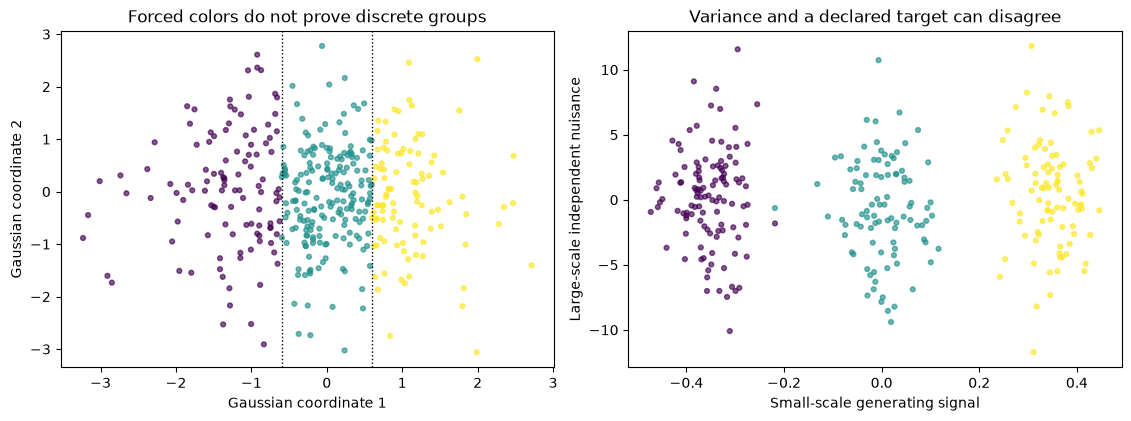

Illustration only: fixed partitions and known generating labels; no model selection or final evaluation.


In [2]:
rng = np.random.default_rng(30620)
null_example = rng.normal(size=(400,2))
forced_colors = np.digitize(null_example[:,0],[-.6,.6])
category = rng.integers(0,3,size=300)
signal = .35*(category-1)+.05*rng.normal(size=300)
nuisance = 4*rng.normal(size=300)
fig,axes = plt.subplots(1,2,figsize=(11.2,4.1),layout='constrained')
axes[0].scatter(*null_example.T,c=forced_colors,s=12,cmap='viridis',alpha=.65)
axes[0].axvline(-.6,color='black',linestyle=':',linewidth=1)
axes[0].axvline(.6,color='black',linestyle=':',linewidth=1)
axes[0].set(xlabel='Gaussian coordinate 1',ylabel='Gaussian coordinate 2',title='Forced colors do not prove discrete groups')
axes[1].scatter(signal,nuisance,c=category,s=12,cmap='viridis',alpha=.65)
axes[1].set(xlabel='Small-scale generating signal',ylabel='Large-scale independent nuisance',title='Variance and a declared target can disagree')
plt.show()
print('Illustration only: fixed partitions and known generating labels; no model selection or final evaluation.')

### Exercise 03.P.09 — Run the complete frozen selection and initialization panel

**Type:** Experimental · **Answer:** Code

For all three tasks, generate label-free partitions and fit/select on training and validation only. Retain every candidate, all eight nonbaseline start records, each candidate's common validation losses, elapsed work and all restart-pair agreements. State the selected procedure and which mathematical/optimization checks have passed before creating any final predictions.

**Expected outcome:** 21 candidate records and 144 bounded restart records with actual results, while all calibration/final rows and external labels remain unused for selection.

In [ ]:
# Your code for Exercise 03.P.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.09**

The null has no discrete generating labels. Its quantization error can improve over the mean because extra prototypes approximate continuous variation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.09**

This snippet depends on 03.P.04–08. It prints summaries but preserves the full models, traces, per-row validation losses and every pair in the bundles. Initialization stability is a diagnostic only; the declared primary selector remains common validation distortion. A baseline has zero starts and no restart-pair summary. All status records are retained; equal work limits do not guarantee equal optimizer quality or runtime.

~~~python
study_tasks = study_datasets(); study_bundles = {}; study_parts = {}; study_start_diagnostics = {}
for name,data in study_tasks.items():
    train,validation,calibration,final = study_partition(data['groups'])
    parts = (train,validation,calibration,final); study_parts[name] = parts
    bundle = study_select(data['X'][train],data['X'][validation]); study_bundles[name] = bundle
    diagnostics = [study_restart_stability(model,data['X'][validation]) for model in bundle['models']]
    study_start_diagnostics[name] = diagnostics
    print('task/split rows',name,[len(p) for p in parts],'groups',[len(np.unique(data['groups'][p])) for p in parts])
    for record,diagnostic in zip(bundle['records'],diagnostics):
        print(record['name'],'validation',round(record['validation_mean'],6),
              'stable/starts',record['stable_starts'],record['starts'],'updates',record['total_updates'],
              'seconds',round(record['fit_and_validation_seconds'],4),'restart ARI',diagnostic['mean'])
    print('frozen selection',name,bundle['specifications'][bundle['chosen']]['name'])

fig,axes = plt.subplots(1,3,figsize=(13.5,4.),layout='constrained')
for ax,(name,bundle) in zip(axes,study_bundles.items()):
    indices = np.arange(len(bundle['records'])); chosen = bundle['chosen']
    ax.bar(indices,[row['validation_mean'] for row in bundle['records']],
           color=['tab:orange' if i == chosen else 'tab:blue' for i in indices])
    ax.set(xticks=indices,xticklabels=['mean','raw\nfull','raw\nPCA1','raw\nPCA2','std\nfull','std\nPCA1','std\nPCA2'],
           ylabel='Common validation mean loss',title=name.replace('_',' '))
    ax.tick_params(axis='x',labelsize=8)
plt.show()
~~~

</details>

### Exercise 03.P.10 — Save and validate a numeric frozen checkpoint

**Type:** Programming · **Answer:** Code

Save the fitted arrays, all start records, per-row validation losses, candidate order, selected index, seed/budgets, versions, data identity and disjoint group partitions in an NPZ artifact with JSON metadata. Load with `allow_pickle=False`. Validate shapes, finiteness, partition coverage/group isolation and selection arithmetic. Resume using the saved fitted arrays, without repeating fitting/selection. Refuse to overwrite an existing fresh checkpoint accidentally.

**Expected outcome:** a numeric round trip preserving predictions and traces, an exact data-version check, and evidence artifacts that support study resumption without pretending to be adversarial access controls.

In [ ]:
# Your code for Exercise 03.P.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.10**

JSON can hold scalar diagnostics and lists; fitted parameter/loss arrays remain ordinary numeric arrays. Atomic replacement protects the previous completed artifact during an interrupted write.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.10**

This snippet depends on 03.P.04–09. It uses only standard-library files/JSON/hash/tempfile utilities. The data hash includes all feature bytes, duplicate-group IDs and any external labels solely as artifact identity; that check is not prediction or model-selection feedback. Audit labels remain excluded from fitting APIs. Loading a checkpoint can validate its internal arithmetic, not prove that a researcher never inspected forbidden information. The experiment's file guard is a protocol aid, not a security boundary against copying an old checkpoint.

~~~python
import hashlib
import json
import os
from pathlib import Path
import tempfile

def study_data_digest(data):
    digest = hashlib.sha256()
    for key in ('X','groups','audit_labels'):
        value = data[key]
        digest.update(key.encode())
        if value is None:
            digest.update(b'none'); continue
        array = np.ascontiguousarray(value)
        digest.update(str(array.dtype).encode()); digest.update(str(array.shape).encode()); digest.update(array.tobytes())
    return digest.hexdigest()

def study_model_array_fields():
    return ('mean','scale','reference_scale','axes','spectrum','centers')

def study_save_checkpoint(path, bundle, data, parts, result=None, phase=None, allow_update=False):
    path = Path(path)
    if path.exists() and not allow_update:
        raise FileExistsError('use a fresh run path; do not silently reset final access')
    phase = bundle['phase'] if phase is None else phase
    if phase not in ('frozen','claimed','complete'):
        raise ValueError('invalid protocol phase')
    metadata = dict(format_version=1,dataset_name=data['name'],data_sha256=study_data_digest(data),
        numpy_version=np.__version__,phase=phase,seed=bundle['seed'],max_steps=bundle['max_steps'],
        specifications=bundle['specifications'],records=bundle['records'],chosen=bundle['chosen'],models=[],
        result_metadata=None if result is None else result['metadata'])
    arrays = dict(groups=np.asarray(data['groups']),validation_losses=bundle['validation_losses'])
    for name,indices in zip(('train','validation','calibration','final'),parts):
        arrays[name+'_indices'] = np.asarray(indices,dtype=np.int64)
    for i,model in enumerate(bundle['models']):
        metadata['models'].append({key:model[key] for key in ('spec','retained_ratio','fit_n','runs','chosen_run')})
        for key in study_model_array_fields():
            arrays[f'model_{i}_{key}'] = np.asarray(model[key])
    if result is not None:
        arrays.update({'result_'+key:np.asarray(value) for key,value in result['arrays'].items()})
    arrays['metadata'] = np.array(json.dumps(metadata,allow_nan=False,sort_keys=True))
    if any(np.asarray(value).dtype.hasobject for value in arrays.values()):
        raise ValueError('object arrays are not checkpoint payloads')
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent,prefix=path.name+'.',suffix='.tmp',delete=False) as handle:
            temporary = Path(handle.name)
            np.savez_compressed(handle,**arrays)
            handle.flush(); os.fsync(handle.fileno())
        os.replace(temporary,path)
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()

def study_load_checkpoint(path):
    with np.load(path,allow_pickle=False) as archive:
        arrays = {key:archive[key].copy() for key in archive.files}
    if 'metadata' not in arrays or arrays['metadata'].shape != () or arrays['metadata'].dtype.kind not in 'US':
        raise ValueError('scalar JSON checkpoint metadata required')
    metadata = json.loads(str(arrays.pop('metadata')))
    if metadata['format_version'] != 1 or metadata['phase'] not in ('frozen','claimed','complete'):
        raise ValueError('unsupported checkpoint format or phase')
    if metadata['numpy_version'] != np.__version__:
        raise ValueError('recorded NumPy version differs; declare a separate replay study')
    groups = arrays['groups']; n = len(groups)
    parts = tuple(arrays[name+'_indices'] for name in ('train','validation','calibration','final'))
    if groups.ndim != 1 or groups.dtype.kind not in 'iu' or not 8 <= n <= 2000 or any(p.ndim != 1 or p.dtype.kind not in 'iu' or len(p) == 0 for p in parts):
        raise ValueError('invalid split/group vectors')
    if not np.array_equal(np.sort(np.concatenate(parts)),np.arange(n)):
        raise ValueError('partitions must cover every row once')
    if any(np.intersect1d(groups[a],groups[b]).size for i,a in enumerate(parts) for b in parts[i+1:]):
        raise ValueError('a duplicate group crosses partitions')
    specifications = metadata['specifications']; count = len(specifications); chosen = metadata['chosen']
    losses = arrays['validation_losses']
    if specifications != study_specifications() or losses.shape != (count,len(parts[1])) or not np.isfinite(losses).all() or np.any(losses < 0):
        raise ValueError('invalid candidates or validation losses')
    records = metadata['records']
    if isinstance(chosen,bool) or not isinstance(chosen,int) or len(records) != count or not np.allclose([r['validation_mean'] for r in records],losses.mean(axis=1),rtol=1e-13,atol=1e-14) or chosen != int(np.argmin(losses.mean(axis=1))):
        raise ValueError('frozen selection arithmetic disagrees')
    models = []
    if len(metadata['models']) != count:
        raise ValueError('missing fitted models')
    for i,info in enumerate(metadata['models']):
        model = dict(info)
        model.update({key:arrays[f'model_{i}_{key}'] for key in study_model_array_fields()})
        if model['mean'].ndim != 1:
            raise ValueError('fitted mean must be one dimensional')
        d = len(model['mean']); r = model['axes'].shape[1] if model['axes'].ndim == 2 else 0
        expected_r = d if specifications[i]['components'] is None else specifications[i]['components']
        if model['spec'] != specifications[i] or model['fit_n'] != len(parts[0]) or not 1 <= d <= 16 or r != expected_r:
            raise ValueError('invalid fitted representation metadata')
        if model['scale'].shape != (d,) or model['reference_scale'].shape != (d,) or model['axes'].shape != (d,r) or model['centers'].shape != (1 if i == 0 else 3,r) or model['spectrum'].shape != (min(len(parts[0]),d),):
            raise ValueError('invalid fitted parameter shape')
        if any(not np.isfinite(model[key]).all() for key in study_model_array_fields()) or np.any(model['spectrum'] < 0) or np.any(model['scale'] <= 0) or np.any(model['reference_scale'] <= 0) or not np.allclose(model['axes'].T@model['axes'],np.eye(r),atol=1e-12,rtol=0):
            raise ValueError('nonfinite or invalid fitted parameter')
        runs = model['runs']; chosen_run = model['chosen_run']
        if i == 0:
            if runs or chosen_run is not None:
                raise ValueError('baseline has no restart experiment')
        else:
            if len(runs) != 8 or isinstance(chosen_run,bool) or not isinstance(chosen_run,int) or not 0 <= chosen_run < 8 or chosen_run != int(np.argmin([run['training_sse'] for run in runs])):
                raise ValueError('invalid restart selection')
            for run in runs:
                trace = np.asarray(run['trace'],dtype=float); centers = np.asarray(run['centers'],dtype=float)
                if centers.shape != (3,r) or not np.isfinite(centers).all() or trace.shape != (run['iterations']+1,) or not np.isfinite(trace).all() or np.any(trace < 0) or not 0 <= run['iterations'] <= metadata['max_steps'] or run['status'] not in ('stable_labels','budget_exhausted') or not np.isclose(trace[-1],run['training_sse'],rtol=1e-12,atol=1e-14):
                    raise ValueError('invalid restart evidence')
            if not np.array_equal(model['centers'],np.asarray(runs[chosen_run]['centers'])):
                raise ValueError('saved centers disagree with chosen start')
        models.append(model)
    bundle = dict(specifications=specifications,models=models,records=records,
        validation_losses=losses,chosen=chosen,phase=metadata['phase'],seed=metadata['seed'],max_steps=metadata['max_steps'])
    result_arrays = {key.removeprefix('result_'):value for key,value in arrays.items() if key.startswith('result_')}
    result = None if metadata['result_metadata'] is None else dict(metadata=metadata['result_metadata'],arrays=result_arrays)
    if (metadata['phase'] == 'complete') != (result is not None):
        raise ValueError('complete phase and final evidence disagree')
    if result is not None:
        final_n = len(parts[3]); calibration_n = len(parts[2]); d = len(models[0]['mean'])
        expected = dict(losses=(count,final_n),clusters=(count,final_n),reconstructions=(count,final_n,d),
            calibration_scores=(2,calibration_n),flags=(2,final_n),pvalue=(2,final_n),rank_numerators=(2,final_n),thresholds=(2,),paired_draws=(400,))
        if set(result_arrays) != set(expected) or any(result_arrays[key].shape != shape for key,shape in expected.items()):
            raise ValueError('invalid saved final array shapes')
        if any(not np.isfinite(value).all() for key,value in result_arrays.items() if key != 'thresholds') or np.isnan(result_arrays['thresholds']).any() or result_arrays['flags'].dtype != np.bool_ or result_arrays['clusters'].dtype.kind not in 'iu' or result_arrays['rank_numerators'].dtype.kind not in 'iu':
            raise ValueError('invalid saved final values')
        if result['metadata']['selected'] != chosen or not np.allclose(result['metadata']['final_means'],result_arrays['losses'].mean(axis=1),rtol=1e-13,atol=1e-14):
            raise ValueError('saved final arithmetic disagrees')
    return bundle,parts,metadata,result

def study_resume_checkpoint(path, data):
    bundle,parts,metadata,result = study_load_checkpoint(path)
    if metadata['dataset_name'] != data['name'] or metadata['data_sha256'] != study_data_digest(data) or not np.array_equal(np.asarray(data['groups']),study_groups(data['X'])):
        raise ValueError('checkpoint data identity or duplicate-group convention differs')
    with np.load(path,allow_pickle=False) as archive:
        if not np.array_equal(np.asarray(data['groups']),archive['groups']):
            raise ValueError('checkpoint group identity differs')
    return bundle,parts,metadata,result
~~~

The next reference uses a new explicit run directory. It does not overwrite a completed study's final-access state. Learners should record their actual directory and resume that checkpoint rather than rerunning selection to make an inconvenient final result disappear.

~~~python
import uuid
study_run_directory = Path('representation-checkpoints')/('run-'+uuid.uuid4().hex[:12])
study_checkpoint_paths = {}
for name,data in study_tasks.items():
    path = study_run_directory/(name+'.npz'); study_checkpoint_paths[name] = path
    study_save_checkpoint(path,study_bundles[name],data,study_parts[name])
    resumed,parts,metadata,result = study_resume_checkpoint(path,data)
    assert result is None and resumed['phase'] == 'frozen'
    for old,new in zip(study_bundles[name]['models'],resumed['models']):
        np.testing.assert_allclose(study_predict(old,data['X'][parts[1]])['losses'],study_predict(new,data['X'][parts[1]])['losses'],rtol=0,atol=0)
    print('saved frozen checkpoint',name,str(path),'selected',resumed['specifications'][resumed['chosen']]['name'])
~~~

</details>

### Exercise 03.P.11 — Claim final access before evaluating and retain its evidence

**Type:** Programming · **Answer:** Code

Implement conservative rank calibration, a conditional Beta flag-rate summary, complete-group paired loss resampling and a final panel for every frozen procedure. Persist a `claimed` state **before** final inference; on success save predictions, reconstructions, per-row losses, flags, external agreement and resampling draws as `complete`. Reject another final call from either claimed or complete state. If interrupted, use saved evidence or disclose any renewed test access.

**Expected outcome:** one auditable final batch, no post-test model selection, no object/pickle payloads, and distinct resampling/model-based/conformal uncertainty statements.

In [ ]:
# Your code for Exercise 03.P.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.11**

An exception after the claim must not reset the checkpoint to frozen. Bootstrap the saved paired loss difference; it requires no new predictions or fitting.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.11**

This snippet depends on 03.P.04–10. Scores are common reconstruction loss, not density. Alpha uses the same explicit decimal-rational convention as the density chapter; rejection uses integer counts. The Beta prior is one/one and its conditional Bernoulli interpretation is a modeling assumption, not a validity theorem. The complete-group bootstrap retains row weights within sampled groups; its percentile range is conditional sensitivity for fixed fitted procedures and observed groups, not guaranteed population coverage or selection/training uncertainty.

The phase guard prevents an accidental second inference in the saved workflow, including after an evaluation exception. It cannot prevent a person from copying old artifacts or deliberately creating a new run. `evaluate` is an optional injected function for an interruption self-check; the ordinary path uses the declared evaluator. A complete checkpoint supplies all final arrays for later analysis, so recomputing metrics does not require another model call.

~~~python
from fractions import Fraction

def study_rank_decisions(calibration, queries, alpha='0.1'):
    calibration = np.asarray(calibration,dtype=float); queries = np.asarray(queries,dtype=float)
    if calibration.ndim != 1 or not 1 <= len(calibration) <= 2000 or queries.ndim != 1 or len(queries) > 2000 or not np.isfinite(calibration).all() or not np.isfinite(queries).all():
        raise ValueError('finite bounded score vectors and nonempty calibration required')
    if isinstance(alpha,(bool,np.bool_)):
        raise ValueError('alpha cannot be Boolean')
    try:
        level = Fraction(str(alpha))
    except (ValueError,ZeroDivisionError,OverflowError) as error:
        raise ValueError('invalid alpha') from error
    if not 0 < level < 1:
        raise ValueError('alpha must lie strictly inside (0,1)')
    n = len(calibration); allowed = level.numerator*(n+1)//level.denominator
    k = n+1-allowed; ordered = np.sort(calibration)
    threshold = np.inf if k > n else float(ordered[k-1])
    numerators = 1+n-np.searchsorted(ordered,queries,side='left')
    flags = numerators <= allowed
    assert np.array_equal(flags,queries > threshold)
    return dict(flags=flags,pvalue=numerators/(n+1),numerators=numerators,threshold=threshold,k=k,n=n)

def study_beta_flags(flagged, n, a=1., b=1.):
    if any(isinstance(v,(bool,np.bool_)) or not isinstance(v,(int,np.integer)) for v in (flagged,n)) or not 0 <= flagged <= n <= 2000:
        raise ValueError('bounded integer flag counts required')
    if any(isinstance(v,(bool,np.bool_)) or np.ndim(v) != 0 or not np.isfinite(v) or not 0 < v <= 10000 for v in (a,b)):
        raise ValueError('finite positive bounded prior shapes required')
    A,B = float(a+flagged),float(b+n-flagged); total = A+B
    return dict(a=A,b=B,posterior_mean=A/total,posterior_variance=A*B/(total*total*(total+1)),
                one_future_flag_probability=A/total)

def study_paired_group_sensitivity(differences, groups, repeats=400, seed=30605):
    differences = np.asarray(differences,dtype=float); groups = np.asarray(groups)
    if differences.ndim != 1 or not 1 <= len(differences) <= 2000 or groups.shape != differences.shape or groups.dtype.kind not in 'iu' or not np.isfinite(differences).all():
        raise ValueError('aligned finite paired differences and integer groups required')
    if isinstance(repeats,(bool,np.bool_)) or not isinstance(repeats,(int,np.integer)) or not 1 <= repeats <= 800:
        raise ValueError('use 1..800 resamples')
    unique = np.unique(groups); rng = np.random.default_rng(seed); means = np.empty(repeats)
    for index in range(repeats):
        selected = rng.choice(unique,size=len(unique),replace=True)
        rows = np.concatenate([np.flatnonzero(groups == group) for group in selected])
        means[index] = differences[rows].mean()
    lower,upper = np.quantile(means,[.025,.975])
    return dict(observed_mean=float(differences.mean()),lower=float(lower),upper=float(upper),
                group_count=len(unique),repeats=int(repeats),seed=int(seed),draws=means)

def study_evaluate_once(bundle, calibration_X, final_X, final_groups, audit_labels=None):
    if bundle['phase'] != 'frozen':
        raise RuntimeError('final access already claimed or complete')
    bundle['phase'] = 'claimed'
    calibration_X = study_rows(calibration_X); final_X = study_rows(final_X)
    outputs = [study_predict(model,final_X) for model in bundle['models']]
    losses = np.array([out['losses'] for out in outputs]); clusters = np.array([out['clusters'] for out in outputs])
    selected = bundle['chosen']; indices = [selected,0]
    calibration_scores = np.array([study_predict(bundle['models'][i],calibration_X)['losses'] for i in indices])
    rules = [study_rank_decisions(score,losses[i]) for i,score in zip(indices,calibration_scores)]
    sensitivity = study_paired_group_sensitivity(losses[selected]-losses[0],final_groups)
    if audit_labels is None:
        agreement = None
    else:
        audit_labels = np.asarray(audit_labels)
        agreement = [study_ari(audit_labels,partition) for partition in clusters]
    flag_summaries = [dict(index=i,flagged=int(rule['flags'].sum()),n=len(final_X),rate=float(rule['flags'].mean()),
                           beta_model=study_beta_flags(int(rule['flags'].sum()),len(final_X))) for i,rule in zip(indices,rules)]
    metadata = dict(selected=selected,primary='common feature-averaged reconstruction loss',alpha='0.1',
        final_means=[float(v) for v in losses.mean(axis=1)],external_ari=agreement,
        flag_summaries=flag_summaries,paired_sensitivity={key:value for key,value in sensitivity.items() if key != 'draws'})
    arrays = dict(losses=losses,clusters=clusters,reconstructions=np.array([out['reconstruction'] for out in outputs]),
        calibration_scores=calibration_scores,flags=np.array([rule['flags'] for rule in rules]),
        pvalue=np.array([rule['pvalue'] for rule in rules]),rank_numerators=np.array([rule['numerators'] for rule in rules]),
        thresholds=np.array([rule['threshold'] for rule in rules]),paired_draws=sensitivity['draws'])
    bundle['phase'] = 'complete'
    return dict(metadata=metadata,arrays=arrays)

def study_finalize_checkpoint(path, data, evaluate=None):
    bundle,parts,metadata,result = study_resume_checkpoint(path,data)
    if bundle['phase'] != 'frozen':
        raise RuntimeError('saved final access already claimed or complete; reuse saved evidence')
    study_save_checkpoint(path,bundle,data,parts,phase='claimed',allow_update=True)
    labels = data['audit_labels']
    evaluator = study_evaluate_once if evaluate is None else evaluate
    result = evaluator(bundle,data['X'][parts[2]],data['X'][parts[3]],data['groups'][parts[3]],
                       None if labels is None else labels[parts[3]])
    if bundle['phase'] != 'complete':
        raise RuntimeError('evaluation did not complete; saved claim remains consumed')
    study_save_checkpoint(path,bundle,data,parts,result=result,allow_update=True)
    return result
~~~

</details>

### Exercise 03.P.12 — Evaluate once, then analyze only saved final arrays

**Type:** Experimental · **Answer:** Code

Finish each frozen checkpoint once. Report all seven common final losses, the preselected procedure's paired difference from the mean baseline, its conditional group-resampling range, calibrated reconstruction flags for selected/baseline, and external ARI where a generating/species label exists. Distinguish the model-based Beta summaries from empirical frequencies and from the exchangeability theorem. Confirm that another final call is refused.

**Expected outcome:** a complete frozen final panel with actual results, preserved access state and no post-test winner replacement.

In [ ]:
# Your code for Exercise 03.P.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.12**

Higher external ARI can coexist with worse compression, and improved compression on a null distribution can coexist with no discrete generating taxonomy.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.12**

This snippet depends on 03.P.04–11 and the saved paths from 03.P.10. The final output and plot are computed from the resulting saved arrays. A different final ranking is reported as a limitation of selection under a small validation sample, not an opportunity to change the frozen selected procedure. Iris label agreement is descriptive and inherits the artifact's sampling/duplicate limitations.

~~~python
study_final_results = {}
for name,data in study_tasks.items():
    result = study_finalize_checkpoint(study_checkpoint_paths[name],data); study_final_results[name] = result
    resumed,parts,metadata,saved = study_resume_checkpoint(study_checkpoint_paths[name],data)
    assert resumed['phase'] == 'complete' and saved is not None
    np.testing.assert_array_equal(saved['arrays']['losses'],result['arrays']['losses'])
    print('final task',name,'selected index',result['metadata']['selected'])
    print('all frozen final means',result['metadata']['final_means'])
    print('external ARI audit',result['metadata']['external_ari'])
    print('paired selected-minus-baseline sensitivity',result['metadata']['paired_sensitivity'])
    print('conditional flag/Beta model summaries',result['metadata']['flag_summaries'])
    try:
        study_finalize_checkpoint(study_checkpoint_paths[name],data)
    except RuntimeError:
        print('accidental second final call refused; analyze saved arrays')
    else:
        raise AssertionError('second final access was allowed')

fig,axes = plt.subplots(1,3,figsize=(13.5,4.),layout='constrained')
for ax,(name,result) in zip(axes,study_final_results.items()):
    means = result['arrays']['losses'].mean(axis=1); chosen = result['metadata']['selected']
    ax.bar(np.arange(7),means,color=['tab:orange' if i == chosen else 'tab:blue' for i in range(7)])
    ax.set(xticks=np.arange(7),xticklabels=['mean','raw\nfull','raw\nPCA1','raw\nPCA2','std\nfull','std\nPCA1','std\nPCA2'],
           ylabel='Common frozen final mean loss',title=name.replace('_',' '))
    ax.tick_params(axis='x',labelsize=8)
plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 03.P.13 — Audit units and training resampling without reopening final data

**Type:** Experimental · **Answer:** Code

Run two predeclared sensitivity studies using training and validation only. First convert all features by positive scales $(1000,.01,5,2)$ and offsets $(7,-3,1,0)$, rerun the seven-procedure selection, and compare common validation losses and partitions. Standardized procedures should be invariant up to floating error; raw procedures need not be. Second, bootstrap training rows four times, refit the originally selected procedure with the same eight-start budget, and compare validation assignments/losses against the original fit. Preserve every replicate and never change the original selection using these diagnostics.

**Expected outcome:** separate evidence for coordinate dependence, training-sample sensitivity and initialization sensitivity, with no new final inference or claims of universal stability.

In [ ]:
# Your code for Exercise 03.P.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.13**

Changing raw units changes the raw algorithm's geometry. Standardization removes this particular positive featurewise unit conversion, not every transformation or modeling assumption.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.13**

This snippet depends on 03.P.04–09. These are declared training/validation diagnostics; neither accesses calibration/final arrays or labels. An apparently invariant choice can still be scientifically inappropriate. Four bootstraps are a bounded sensitivity probe, not an estimated population confidence procedure. Bootstrap duplicates retain multiplicity as repeated weighted observations. The saved original protocol and selected index are never mutated.

~~~python
def study_sensitivity(train, validation, original_bundle, repeats=4, seed=30606):
    train = study_rows(train); validation = study_rows(validation)
    if train.shape[1] != 4:
        raise ValueError('the declared unit intervention uses four features')
    if isinstance(repeats,(bool,np.bool_)) or not isinstance(repeats,(int,np.integer)) or not 1 <= repeats <= 8:
        raise ValueError('use 1..8 bootstrap refits')
    scale = np.array([1000.,.01,5.,2.]); offset = np.array([7.,-3.,1.,0.])
    converted = study_select(train*scale+offset,validation*scale+offset,
                             original_bundle['seed'],original_bundle['max_steps'])
    unit_records = []
    for old,new in zip(original_bundle['models'],converted['models']):
        a = study_predict(old,validation); b = study_predict(new,validation*scale+offset)
        unit_records.append(dict(name=old['spec']['name'],original_mean=float(a['losses'].mean()),
            converted_mean=float(b['losses'].mean()),max_loss_difference=float(np.max(np.abs(a['losses']-b['losses']))),
            ari=study_ari(a['clusters'],b['clusters'])))
    selected = original_bundle['chosen']; original = original_bundle['models'][selected]
    reference_partition = study_predict(original,validation)['clusters']
    rng = np.random.default_rng(seed); resamples = []
    for index in range(repeats):
        rows = rng.integers(len(train),size=len(train))
        fitted = study_fit_model(train[rows],original['spec'],original_bundle['seed'],original_bundle['max_steps'])
        output = study_predict(fitted,validation)
        # A bootstrap's own scaling is appropriate inside its fitted procedure.
        # For cross-replicate loss reporting, retain the original study's metric.
        losses = np.mean(((validation-output['reconstruction'])/original['reference_scale'])**2,axis=1)
        resamples.append(dict(repeat=index,indices=rows,validation_mean=float(losses.mean()),
            ari=study_ari(reference_partition,output['clusters']),runs=fitted['runs']))
    return dict(unit_records=unit_records,converted_selected=converted['chosen'],
                bootstrap_records=resamples,original_selected=selected)

study_sensitivity_results = {}
for name,data in study_tasks.items():
    train,validation,_,_ = study_parts[name]
    sensitivity = study_sensitivity(data['X'][train],data['X'][validation],study_bundles[name])
    study_sensitivity_results[name] = sensitivity
    print('training/validation sensitivity',name,'original/converted selection',sensitivity['original_selected'],sensitivity['converted_selected'])
    print('unit records',sensitivity['unit_records'])
    print('bootstrap records',[(r['repeat'],r['validation_mean'],r['ari']) for r in sensitivity['bootstrap_records']])
    for record in sensitivity['unit_records']:
        if record['name'].startswith('standardized') or record['name'] == 'mean':
            assert record['max_loss_difference'] < 1e-9 and abs(record['ari']-1.) < 1e-12
~~~

</details>

### Exercise 03.P.14 — Explain the null, the external audit, and the stability claim

**Type:** Critical · **Answer:** Markdown

Interpret the complete results without substituting a new objective after seeing them. Does lower distortion on the Gaussian null discover discrete groups? Does high ARI with Iris species prove the representation is best for compression? Distinguish repeated initialization, training bootstrap, final group resampling and a Beta flag posterior. State which claim each does and does not support.

**Expected outcome:** a bounded result statement with competing explanations and no semantic, optimization or uncertainty overclaim.

**Your response to Exercise 03.P.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.14**

The baseline's one cluster is perfectly stable but not automatically the scientific answer. Different sources of randomness need different repeat designs.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.14**

Three prototypes can approximate continuous Gaussian variation better than a single mean without there being a discrete generating category. Stability can reflect a reproducible quantization of nuisance variation or a strong algorithmic bias. External species/component labels answer a different agreement question and were not the selector's objective; they cannot retroactively justify a new chosen representation. Initialization comparisons hold training rows fixed, training bootstraps perturb their empirical distribution and refit, final group resampling perturbs observed paired losses with models fixed, and the Beta posterior assumes a prior plus conditional IID Bernoulli flags. None alone measures all training/selection/calibration/deployment uncertainty. A supported claim names the exact tasks, three-prototype budget, common metric, candidate grid and realized work, and discusses artifact dependence, units, small samples and model mismatch.

</details>

### A bounded primary-source study

| Primary source | Required preparation and passage | Local question and reproduction boundary |
| --- | --- | --- |
| Andrew Ng, [CS229 PCA notes](https://see.stanford.edu/materials/aimlcs229/cs229-notes10.pdf), preprocessing on p.2 and projections on pp.5–6; accessed October 25, 2026 | Stage 03 PCA/SVD and explicit coordinate metrics | Translate the projection into row-wise observations, independently verify orthogonality/reconstruction, and test the metric cross term above. The file supplies no explicit revision date. Do not extend an unweighted projection argument to every reporting metric. |
| Ulrike von Luxburg, [Clustering Stability: An Overview](https://arxiv.org/abs/1007.1075v1), v1 July 7, 2010, §2 equation 2.1 and the perturbation/comparison discussion on printed pp.4–7; accessed October 25, 2026 | Stage 03 clustering, ARI, independent sampling and the distinction between ideal and finite optimization | Compare changing initialization with changing training samples, and specify the common-domain extension. Reproduce only the bounded local diagnostics, not the paper's asymptotic results or a theorem that the most stable procedure discovers the correct taxonomy. |

### Exercise 03.P.15 — Translate a stability expectation to this finite experiment

**Type:** Critical · **Answer:** Markdown

Read the selected stability passage and name the random objects in its expectation. Compare them with the capstone's eight fixed-data starts and four training bootstraps. Explain the nearest-center extension to common validation rows and whether the implemented ARI summary estimates the paper's exact population quantity.

**Expected outcome:** a precise source-to-experiment mapping, identified departures and a modest supported claim.

**Your response to Exercise 03.P.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.15**

An expectation over new independent samples is not automatically estimated by repeatedly optimizing one fixed sample or bootstrapping one empirical distribution.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.15**

The paper's equation describes an expected distance between partitions obtained from separate samples under a specified clustering procedure. Our eight-start comparison instead holds observations fixed and varies initialization; its finite optimizer and best-start choice are part of that procedure. Four training bootstraps draw from one observed empirical distribution, not fresh unknown-population samples, and compare with the original fit rather than all independent population pairs. Nearest-center assignment extends each learned partition to the same validation rows, making the comparison domain explicit. ARI and that finite reference comparison are declared choices; they are not asserted to be an unbiased estimate of equation 2.1 or its asymptotic limit. The result supports observed sensitivity for these interventions and budgets, with possible trivial stability, representation dependence and sampling limitations.

</details>

## 8. Review questions and knowledge checks

### Exercise 03.P.16 — Design independent mathematical and procedural checks

**Type:** Numerical · **Answer:** Markdown

List independent oracles for fixed-assignment gradients, the hand optimum, PCA projectors/reconstruction, the common metric, ARI, exact rank decisions, Beta moments and group-resampling arithmetic. Add held-out-outlier isolation, malformed checkpoint, numeric round-trip, duplicate-group overlap, budget exhaustion and an exception after the persisted final claim. Identify which outcomes establish implementation correctness and which require experimental evidence.

**Expected outcome:** separate scalar, geometric, probabilistic and state-transition checks that do not execute or grade unfinished learner answers.

**Your response to Exercise 03.P.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.16**

Finite differences should use a separately written scalar objective. A checkpoint's phase must survive reloading after an injected evaluation error.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.16**

Central-difference an independent scalar sum-SSE at fixed assignments and compare every center coordinate, including empty centers. Enumerate the tiny two-group objective and verify the hand values without assuming general Lloyd optimality. Check an independent covariance eigenspace/projector and full reconstruction, calculating the common row loss with scalar loops. Verify ARI via pair counts/fixed-margin expectation and label permutations; enumerate held-out score ranks with ties. Use rational Beta moments and explicit group-index resampling as separate probability/arithmetic oracles. Fit with and without an extreme held-out row while keeping training fixed and verify unchanged fitted arrays. Round-trip numeric checkpoints and reject malformed dimensions, overlapping groups, changed data bytes and inconsistent selection. Inject an exception after the disk claim, reload and confirm another final call is refused. These establish specified calculations and protocol behavior, not semantic cluster truth, global optimization or universal ranking.

</details>

### Exercise 03.P.17 — Write the technical report and connect it to modern representations

**Type:** Critical · **Answer:** Markdown

Use the report template to state an actual supported claim, all evidence and limitations. Explain how these checks would transfer to later neural embeddings, token representations or latent generative models, and what must change before claiming results about them. Identify one bounded follow-up with a preregistered alternative explanation and compute budget; do not invent results for that follow-up.

**Expected outcome:** separate Explain / Implement / Verify / Evaluate evidence, a reproducible artifact trail, and a research question whose conclusion is narrower than its motivation.

**Your response to Exercise 03.P.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.P.17**

A learned representation introduces additional fitting data, architectural choices and possible supervised information. It does not remove the selection, metric or evaluation boundaries.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.P.17**

A report could conclude that one declared procedure had lower realized common reconstruction loss than the mean baseline on a named task, supported by full candidate/start records and paired final sensitivity, while admitting validation noise and limited semantic agreement. Include exact objective units, split/groups, code/version/seed, arrays, checkpoints and actual timing/memory, with unresolved checks. Transferring to neural embeddings requires declaring how the embedding was trained/selected, which data and labels it saw, and whether a density is in embedding or input space. Finite optimization, representation collapse, dimension, metric and shift can change every interpretation. A bounded follow-up might vary the nuisance scale on newly generated tasks with fixed seeds/budgets and a declared common metric, testing whether a claimed benefit persists. It requires new held-out data and a new protocol; the present final panel cannot be reused as an unconsumed test for that design.

</details>

## 9. Summary and next learning steps

A representation study is complete when the question, mathematics, implementation, information boundaries and evidence can be inspected independently. This project uses a common full-feature reconstruction metric to compare a fixed compression task, keeps optimization diagnostics separate from selection scores, and uses a null population and external labels to challenge semantic interpretations. Calibration and model-based inference remain conditional on their different assumptions; a saved final panel supports analysis without repeated prediction.

Submit the completed starter, full candidate/start/sensitivity evidence, numeric selection/final checkpoints, independent checks, actual resource record and report. Organize resumable sessions around (1) protocol and oracles, (2) verified implementations, (3) selection and a frozen checkpoint, and (4) claimed final evaluation and reporting. Roughly two hours is a session target, not a required program runtime. Keep standard working memory below 6 GiB host; this project needs no GPU. The [stage guide](../../notebooks/03-unsupervised-learning/README.md) records measured reference presets; measure learner implementations separately.

Advance only with evidence that you can **explain** assumptions/objectives, **implement** the declared algorithms, **verify** independent values and procedural isolation, and **evaluate** what the results do and do not support. Continue to the existing [Stage 04 neural-network foundations](../../notebooks/04-neural-networks/README.md), where representations become learned nonlinear functions and the same habits of objective, derivative, data and claim verification remain essential.